In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [4]:
from google.colab import drive

dataset_path = '/content/drive/MyDrive/dataset/'
train_path = os.path.join(dataset_path, 'train')       # used for training + validation
test_path = os.path.join(dataset_path, 'validation')   # held-out test set

class_names = sorted([
    d for d in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, d))
])
print("Detected classes:", class_names)

for split, split_path in [('train', train_path), ('validation (test)', test_path)]:
    total = 0
    print(f"{split}:")
    for c in class_names:
        folder = os.path.join(split_path, c)
        n_images = len([f for f in os.listdir(folder)
                         if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        total += n_images
        print(f"  class '{c}': {n_images} images")
    print("  TOTAL:", total)

Detected classes: ['1', '2', '3']
train:
  class '1': 800 images
  class '2': 800 images
  class '3': 800 images
  TOTAL: 2400
validation (test):
  class '1': 100 images
  class '2': 100 images
  class '3': 100 images
  TOTAL: 300


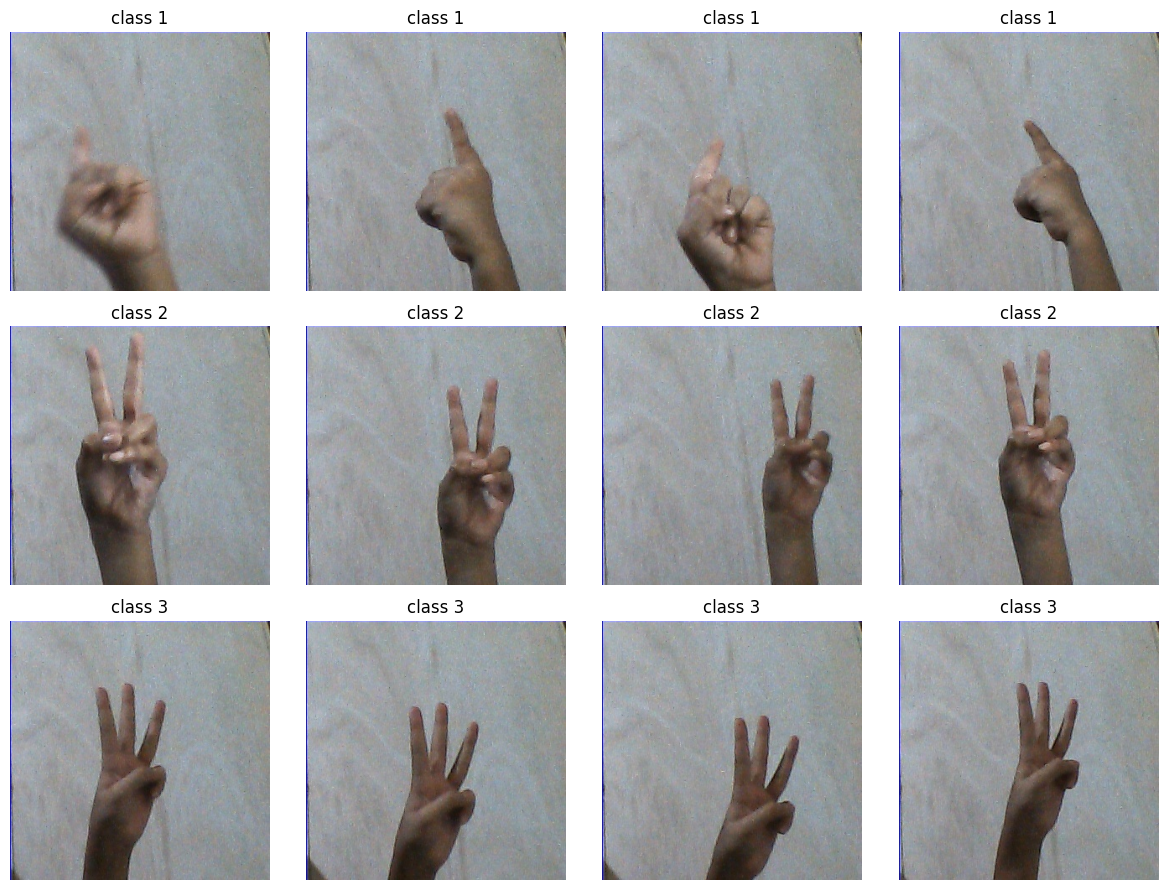

In [5]:
fig, axes = plt.subplots(len(class_names), 4, figsize=(12, 3 * len(class_names)))
for row, c in enumerate(class_names):
    folder = os.path.join(train_path, c)
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))][-4:]
    for col, fname in enumerate(files):
        img = keras.utils.load_img(os.path.join(folder, fname))
        ax = axes[row, col] if len(class_names) > 1 else axes[col]
        ax.imshow(img)
        ax.set_title(f"class {c}")
        ax.axis('off')
plt.tight_layout()
plt.show()


In [19]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 10

# train folder -> 85% train, 15% validation (for early stopping)
# validation folder -> test set (never used for training)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

class_names = train_ds.class_names
print("Classes (in label order):", class_names)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:  ", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches: ", tf.data.experimental.cardinality(test_ds).numpy())

Found 2400 files belonging to 3 classes.
Using 2040 files for training.
Found 2400 files belonging to 3 classes.
Using 360 files for validation.
Found 300 files belonging to 3 classes.
Classes (in label order): ['1', '2', '3']
Train batches: 204
Val batches:   36
Test batches:  30


In [20]:
# Normalization
normalization_layer = layers.Rescaling(1./255)

AUTOTUNE = tf.data.AUTOTUNE
train_ds_perf = train_ds.cache().shuffle(2500, seed=SEED).prefetch(buffer_size=AUTOTUNE)
val_ds_perf = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds_perf = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

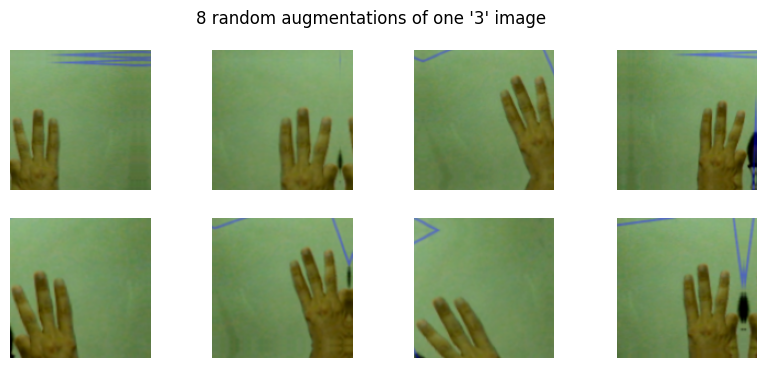

In [21]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),        # mirror the image left-right
    layers.RandomRotation(0.08),            # rotate up to ~ +/-29 degrees (0.08 * 360)
    layers.RandomZoom(0.15),                # zoom in/out up to 15%
    layers.RandomContrast(0.15),            # vary contrast, simulates different lighting
    layers.RandomTranslation(0.1, 0.1),     # shift the image slightly, simulates hand not centered
], name="data_augmentation")

for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 4))
    first_image = images[0]
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        augmented = data_augmentation(tf.expand_dims(first_image, 0), training=True)
        plt.imshow(augmented[0].numpy().astype("uint8"))
        plt.axis("off")
    plt.suptitle(f"8 random augmentations of one '{class_names[labels[0]]}' image")
    plt.show()


In [22]:
#  Logistic Regression on raw pixels
def dataset_to_numpy(ds):
    X, y = [], []
    for images, labels in ds:
        images = images.numpy() / 255.0
        X.append(images.reshape(images.shape[0], -1))
        y.append(labels.numpy())
    return np.concatenate(X), np.concatenate(y)

X_train, y_train = dataset_to_numpy(train_ds)
X_val, y_val = dataset_to_numpy(val_ds)
X_test, y_test = dataset_to_numpy(test_ds)

print("X_train shape:", X_train.shape, " (n_samples, n_pixels*3channels)")

baseline_model = LogisticRegression(max_iter=2000, random_state=SEED)
baseline_model.fit(X_train, y_train)

baseline_val_preds = baseline_model.predict(X_val)
print("Baseline validation accuracy:", accuracy_score(y_val, baseline_val_preds))


X_train shape: (2040, 49152)  (n_samples, n_pixels*3channels)
Baseline validation accuracy: 0.6166666666666667


In [23]:
# a small CNN trained from scratch
num_classes = len(class_names)

cnn_model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
], name="cnn_from_scratch")

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
cnn_model.summary()


Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,419 (4.09 MB)

 Trainable params: 1,072,419 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
EPOCHS = 25

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=6, restore_best_weights=True
)

history_cnn = cnn_model.fit(
    train_ds_perf,
    validation_data=val_ds_perf,
    epochs=EPOCHS,
    callbacks=[early_stop]
)


Epoch 1/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 38s 157ms/step - accuracy: 0.3373 - loss: 1.1022 - val_accuracy: 0.2917 - val_loss: 1.0993
Epoch 2/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 32s 158ms/step - accuracy: 0.3480 - loss: 1.0990 - val_accuracy: 0.3028 - val_loss: 1.0982
Epoch 3/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 30s 149ms/step - accuracy: 0.3348 - loss: 1.0938 - val_accuracy: 0.3000 - val_loss: 1.0947
Epoch 4/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 32s 157ms/step - accuracy: 0.3221 - loss: 1.0955 - val_accuracy: 0.3444 - val_loss: 1.1048
Epoch 5/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 40s 154ms/step - accuracy: 0.3338 - loss: 1.0945 - val_accuracy: 0.3000 - val_loss: 1.0918
Epoch 6/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 31s 154ms/step - accuracy: 0.3392 - loss: 1.0943 - val_accuracy: 0.3028 - val_loss: 1.0932
Epoch 7/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 32s 156ms/step - accuracy: 0.3279 - loss: 1.0963 - val_accuracy: 0.3028 - val_loss: 1.0942
Epoch 8/25
204/204 ━━━━━━━━━━━━━━━━━━━━ 31s 151ms/step - accuracy: 0.3191 - loss: 1

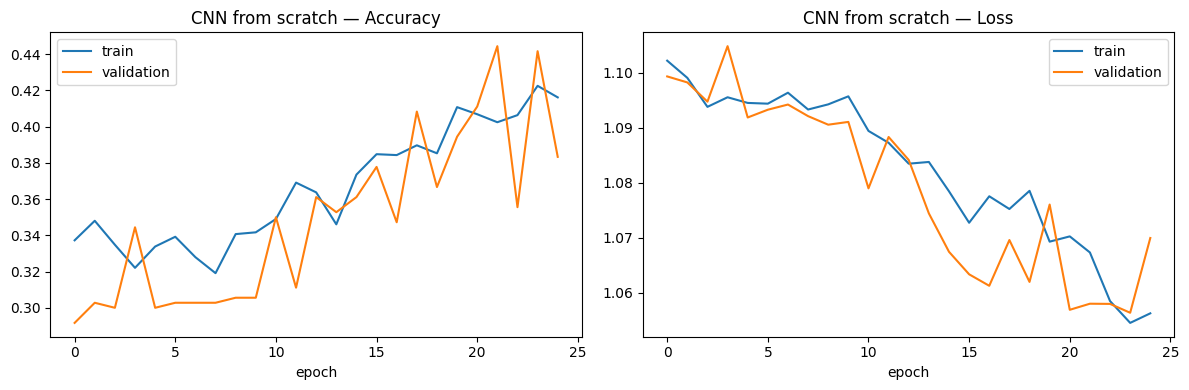

In [ ]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history['accuracy'], label='train')
    axes[0].plot(history.history['val_accuracy'], label='validation')
    axes[0].set_title(f'{title} - Accuracy')
    axes[0].set_xlabel('epoch'); axes[0].legend()

    axes[1].plot(history.history['loss'], label='train')
    axes[1].plot(history.history['val_loss'], label='validation')
    axes[1].set_title(f'{title} - Loss')
    axes[1].set_xlabel('epoch'); axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_cnn, "CNN from scratch")


In [ ]:
def evaluate_keras_model(model, ds, name):
    y_true, y_pred = [], []
    for images, labels in ds:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
    print(f"=== {name} ===")
    print(f"Accuracy:  {acc:.3f}")
    print(f"Precision (macro avg): {precision:.3f}")
    print(f"Recall (macro avg):    {recall:.3f}")
    print(f"F1-score (macro avg):  {f1:.3f}\n")
    print(classification_report(y_true, y_pred, target_names=class_names))
    return y_true, y_pred, acc, precision, recall, f1

def plot_confusion(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.show()


=== Baseline: Logistic Regression ===
Accuracy:  0.397
Precision (macro avg): 0.395
Recall (macro avg):    0.397
F1-score (macro avg):  0.383

              precision    recall  f1-score   support

           1       0.47      0.39      0.43       100
           2       0.33      0.21      0.26       100
           3       0.39      0.59      0.47       100

    accuracy                           0.40       300
   macro avg       0.39      0.40      0.38       300
weighted avg       0.39      0.40      0.38       300



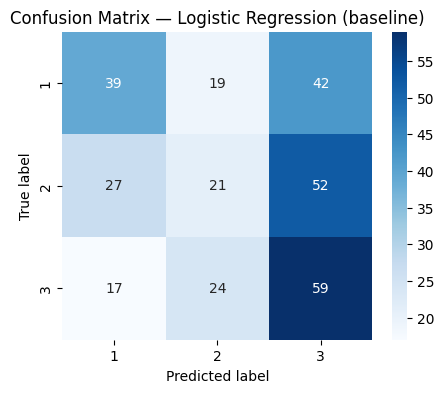

In [28]:
#Logistic Regression
baseline_pred = baseline_model.predict(X_test)
baseline_acc = accuracy_score(y_test, baseline_pred)
b_precision, b_recall, b_f1, _ = precision_recall_fscore_support(y_test, baseline_pred, average='macro')
print("=== Baseline: Logistic Regression ===")
print(f"Accuracy:  {baseline_acc:.3f}")
print(f"Precision (macro avg): {b_precision:.3f}")
print(f"Recall (macro avg):    {b_recall:.3f}")
print(f"F1-score (macro avg):  {b_f1:.3f}\n")
print(classification_report(y_test, baseline_pred, target_names=class_names))
plot_confusion(y_test, baseline_pred, "Logistic Regression (baseline)")


=== CNN from scratch ===
Accuracy:  0.390
Precision (macro avg): 0.393
Recall (macro avg):    0.390
F1-score (macro avg):  0.381

              precision    recall  f1-score   support

           1       0.44      0.34      0.38       100
           2       0.36      0.27      0.31       100
           3       0.38      0.56      0.45       100

    accuracy                           0.39       300
   macro avg       0.39      0.39      0.38       300
weighted avg       0.39      0.39      0.38       300



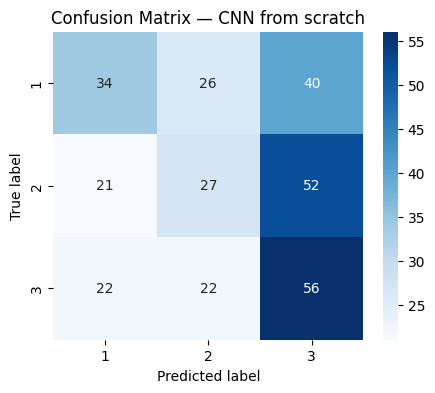

In [29]:
# CNN from scratch
cnn_true, cnn_pred, cnn_acc, cnn_prec, cnn_rec, cnn_f1 = evaluate_keras_model(cnn_model, test_ds_perf, "CNN from scratch")
plot_confusion(cnn_true, cnn_pred, "CNN from scratch")


In [30]:
# comparison
results = pd.DataFrame({
    "Model": ["Logistic Regression (baseline)", "CNN from scratch"],
    "Accuracy": [baseline_acc, cnn_acc],
    "Precision (macro)": [b_precision, cnn_prec],
    "Recall (macro)": [b_recall, cnn_rec],
    "F1-score (macro)": [b_f1, cnn_f1],
})
results = results.round(3)
print(results.to_string(index=False))
results

                         Model  Accuracy  Precision (macro)  Recall (macro)  F1-score (macro)
Logistic Regression (baseline)     0.397              0.395           0.397             0.383
              CNN from scratch     0.390              0.393           0.390             0.381


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression (baseline),0.397,0.395,0.397,0.383
1,CNN from scratch,0.390,0.393,0.390,0.381
